# 04 · Avaliação: placar das três configurações, alucinações e erros reais

Os mesmos **37 casos de teste** (`avaliacao/casos_teste.json`: 27 com resposta na base e 10 "não consta") são respondidos por:

| Configuração | O que é |
|---|---|
| **C1 · LLM base sem contexto** | `Qwen2.5-1.5B-Instruct` sozinho, sem a base (mesmo formato JSON pedido) |
| **C2 · RAG simples** | busca dos 3 trechos mais parecidos + modelo base |
| **C3 · RAG + LoRA** | mesma busca + modelo especializado no notebook 02 |
| **Sistema final** | C3 + limiar de recusa escolhido no notebook 01 (o que roda na interface e na API) |

C2 e C3 rodam **sem limiar**, para comparar só o efeito do LoRA. A geração é determinística (greedy) para o resultado ser reprodutível.

**Métricas** (calculadas por `src/agrofacil.py`, sem ajuste manual):
- `json_valido_%`: a saída é um JSON no formato `{resposta, fonte_id, status}`;
- `resposta_correta_%`: nas perguntas com resposta na base, o texto contém os termos do gabarito;
- `resposta_com_citacao_correta_%`: correta **e** citando o trecho certo;
- `recusa_correta_nao_consta_%`: nas perguntas fora da base, respondeu "não consta";
- `alucinacao_nao_consta_%`: nas perguntas fora da base, **inventou** uma resposta;
- `resposta_errada_afirmada_%`: nas perguntas da base, afirmou algo sem os termos do gabarito;
- `recusa_indevida_%`: recusou uma pergunta que tinha resposta.

In [ ]:
import os, sys, subprocess
from pathlib import Path

REPO = "https://github.com/palomari/agrofacil-genai.git"
try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive")
except ImportError:
    pass  

if not Path("src/agrofacil.py").exists():
    if Path("../src/agrofacil.py").exists():
        os.chdir("..")
    else:
        if not Path("agrofacil-genai").exists():
            subprocess.run(["git", "clone", REPO], check=True)
        os.chdir("agrofacil-genai")

assert Path("src/agrofacil.py").exists(), (
    "Versão antiga do repositório nesta pasta. Apague a pasta agrofacil-genai do Drive e rode de novo.")
sys.path.insert(0, os.getcwd())
print("Raiz do projeto:", os.getcwd())
print("Versão:", subprocess.run(["git", "log", "-1", "--format=%h %cd"], capture_output=True, text=True).stdout.strip())

Mounted at /content/drive
Raiz do projeto: /content/drive/MyDrive/agrofacil-genai
Versão: db82db8 Wed Nov 18 17:44:20 2026 -0300


In [2]:
%pip install -q -r requirements.txt

In [3]:
import json, re
from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm
from src import agrofacil as af

testes = af.carregar_testes()
cfg = af.carregar_config()
print("Configuração da busca:", cfg)
buscador = af.Buscador(af.carregar_base(), cfg["encoder"])
model, tok = af.carregar_modelo(adapter=None)

PASTA = Path("avaliacao/resultados"); PASTA.mkdir(parents=True, exist_ok=True)
resultados = {}

def rodar(nome, **kw):
    res = [af.responder(c["pergunta"], model, tok, buscador=buscador, k=cfg.get("k", 3), **kw)
           for c in tqdm(testes, desc=nome)]
    slug = re.sub(r"[^a-z0-9]+", "_", af.normalizar(nome)).strip("_")
    with open(PASTA / f"{slug}.jsonl", "w", encoding="utf-8") as f:
        for c, r in zip(testes, res):
            f.write(json.dumps({"caso": c["id"], **r, **af.avaliar_caso(c, r)}, ensure_ascii=False) + "\n")
    resultados[nome] = res
    return res

Configuração da busca: {'encoder': 'sentence-transformers/all-MiniLM-L6-v2', 'limiar': 0.425, 'k': 3}


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (13 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [4]:
rodar("C1 · LLM base sem contexto", modo="sem_contexto")
rodar("C2 · RAG simples", modo="rag", limiar=None)

C1 · LLM base sem contexto:   0%|          | 0/37 [00:00<?, ?it/s]

C2 · RAG simples:   0%|          | 0/37 [00:00<?, ?it/s]

[{'pergunta': 'O que significa quando o INMET emite um aviso na cor laranja?',
  'modo': 'rag',
  'limiar': None,
  'score_top1': 0.5497195720672607,
  'trechos_recuperados': [{'id': 'T06', 'score': 0.5497},
   {'id': 'T01', 'score': 0.5442},
   {'id': 'T08', 'score': 0.5385}],
  'aviso': 'Orientação informativa baseada em fontes oficiais. Não substitui a Defesa Civil nem a assistência técnica. Em emergência, ligue 199 (Defesa Civil) ou 193 (Bombeiros).',
  'resposta': 'Não consta na base de conhecimento.',
  'status': 'nao_consta',
  'fonte_id': None,
  'fonte': None,
  'url': None,
  'json_valido': True,
  'citacao_valida': None,
  'origem': 'modelo',
  'bruto': '{"resposta":"O INMET emite avisos meteorológicos sobre tempo severo previsto, como chuvas intensas, tempestades, vendavais, baixa umidade do ar e ondas de calor. Os avisos podem ser emitidos com até cinco dias de antecedência e são atualizados diariamente em avisos.inmet.gov.br.","fonte_id":null,"status":"nao_consta"}',
  'l

In [5]:
assert af.CAMINHO_ADAPTER.exists(), "Rode o notebook 02 (ou baixe o adaptador para modelos/agrofacil_adapter)."
model = af.aplicar_adapter(model, af.CAMINHO_ADAPTER)
rodar("C3 · RAG + LoRA", modo="rag", limiar=None)
rodar("Sistema final · RAG + LoRA + limiar", modo="rag", limiar=cfg["limiar"])

C3 · RAG + LoRA:   0%|          | 0/37 [00:00<?, ?it/s]

Sistema final · RAG + LoRA + limiar:   0%|          | 0/37 [00:00<?, ?it/s]

[{'pergunta': 'O que significa quando o INMET emite um aviso na cor laranja?',
  'modo': 'rag',
  'limiar': 0.425,
  'score_top1': 0.5497195720672607,
  'trechos_recuperados': [{'id': 'T06', 'score': 0.5497},
   {'id': 'T01', 'score': 0.5442},
   {'id': 'T08', 'score': 0.5385}],
  'aviso': 'Orientação informativa baseada em fontes oficiais. Não substitui a Defesa Civil nem a assistência técnica. Em emergência, ligue 199 (Defesa Civil) ou 193 (Bombeiros).',
  'resposta': 'O INMET usa a cor laranja para indicar perigo. Isso significa que há uma chance de haver uma chuva forte, tempestade, vendaval, baixa umidade do ar ou onda de calor. É importante tomar precauções.',
  'status': 'ok',
  'fonte_id': 'T01',
  'fonte': 'INMET - Aviso meteorológico ou alerta? Entenda a diferença',
  'url': 'https://portal.inmet.gov.br/noticias/aviso-meteorológico-e-alerta-entenda-a-diferença',
  'json_valido': True,
  'citacao_valida': True,
  'origem': 'modelo',
  'bruto': '{"resposta": "O INMET usa a cor 

## Placar

In [6]:
placar = pd.DataFrame([af.resumo_config(n, testes, r) for n, r in resultados.items()])
placar.to_csv("avaliacao/placar.csv", index=False)
placar.set_index("configuracao").T

configuracao,C1 · LLM base sem contexto,C2 · RAG simples,C3 · RAG + LoRA,Sistema final · RAG + LoRA + limiar
json_valido_%,16.20,91.90,100.00,100.00
resposta_correta_%,0.00,44.40,81.50,81.50
resposta_com_citacao_correta_%,0.00,25.90,74.10,74.10
recusa_correta_nao_consta_%,0.00,100.00,100.00,100.00
alucinacao_nao_consta_%,30.00,0.00,0.00,0.00
resposta_errada_afirmada_%,11.10,0.00,14.80,14.80
recusa_indevida_%,0.00,44.40,3.70,3.70
acerto_geral_%,0.00,45.90,81.10,81.10
latencia_media_s,2.85,3.98,7.79,7.63


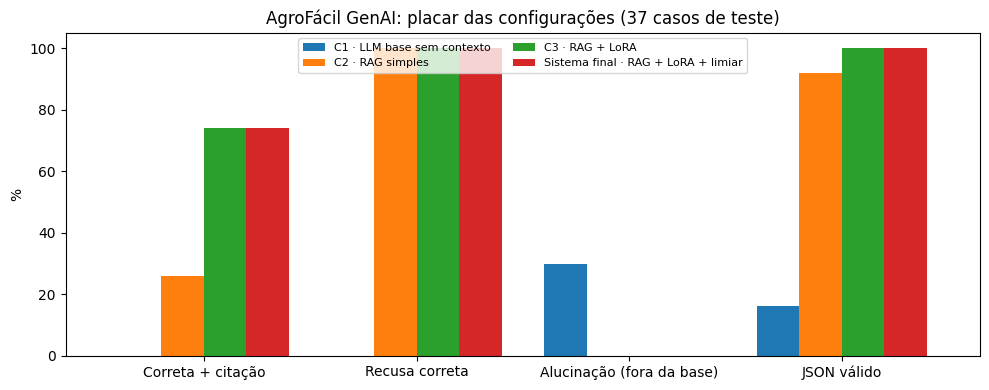

In [7]:
import matplotlib.pyplot as plt

metricas = ["resposta_com_citacao_correta_%", "recusa_correta_nao_consta_%", "alucinacao_nao_consta_%", "json_valido_%"]
rotulos = ["Correta + citação", "Recusa correta", "Alucinação (fora da base)", "JSON válido"]
ax = placar.set_index("configuracao")[metricas].T.set_axis(rotulos).plot.bar(figsize=(10, 4), rot=0, width=.8)
ax.set_ylabel("%"); ax.set_ylim(0, 105); ax.legend(fontsize=8, loc="upper center", ncol=2)
ax.set_title("AgroFácil GenAI: placar das configurações (37 casos de teste)")
plt.tight_layout(); plt.savefig("avaliacao/placar.png", dpi=120); plt.show()

In [ ]:
P = placar.set_index("configuracao")
c1, c2, c3, fin = P.index.tolist()
m = lambda cfgname, col: P.loc[cfgname, col]
linhas = [
    f"- **Base vs. RAG:** a resposta correta com citação vai de {m(c1,'resposta_com_citacao_correta_%')}% (C1, que não tem fonte para citar) "
    f"para {m(c2,'resposta_com_citacao_correta_%')}% no RAG simples; a resposta correta sem exigir citação vai de "
    f"{m(c1,'resposta_correta_%')}% para {m(c2,'resposta_correta_%')}%.",
    f"- **Alucinação fora da base:** C1 inventa resposta em {m(c1,'alucinacao_nao_consta_%')}% das perguntas 'não consta', "
    f"C2 em {m(c2,'alucinacao_nao_consta_%')}%, C3 em {m(c3,'alucinacao_nao_consta_%')}% e o sistema final em {m(fin,'alucinacao_nao_consta_%')}%.",
    f"- **Efeito do LoRA (C2 → C3):** JSON válido {m(c2,'json_valido_%')}% → {m(c3,'json_valido_%')}%; "
    f"correta + citação {m(c2,'resposta_com_citacao_correta_%')}% → {m(c3,'resposta_com_citacao_correta_%')}%; "
    f"recusa correta {m(c2,'recusa_correta_nao_consta_%')}% → {m(c3,'recusa_correta_nao_consta_%')}%; "
    f"recusa indevida {m(c2,'recusa_indevida_%')}% → {m(c3,'recusa_indevida_%')}%.",
    f"- **Efeito do limiar (C3 → final):** recusa correta {m(c3,'recusa_correta_nao_consta_%')}% → {m(fin,'recusa_correta_nao_consta_%')}%, "
    f"com recusa indevida {m(c3,'recusa_indevida_%')}% → {m(fin,'recusa_indevida_%')}% (o custo de recusar mais).",
    f"- **Latência média por pergunta (T4):** C1 {m(c1,'latencia_media_s')} s, C2 {m(c2,'latencia_media_s')} s, "
    f"C3 {m(c3,'latencia_media_s')} s, final {m(fin,'latencia_media_s')} s.",
]
interpretacao = "\n".join(linhas)
print(interpretacao)

- **Base vs. RAG:** a resposta correta com citação vai de 0.0% (C1, que não tem fonte para citar) para 25.9% no RAG simples; a resposta correta sem exigir citação vai de 0.0% para 44.4%.
- **Alucinação fora da base:** C1 inventa resposta em 30.0% das perguntas 'não consta', C2 em 0.0%, C3 em 0.0% e o sistema final em 0.0%.
- **Efeito do LoRA (C2 → C3):** JSON válido 91.9% → 100.0%; correta + citação 25.9% → 74.1%; recusa correta 100.0% → 100.0%; recusa indevida 44.4% → 3.7%.
- **Efeito do limiar (C3 → final):** recusa correta 100.0% → 100.0%, com recusa indevida 3.7% → 3.7% (o custo de recusar mais).
- **Latência média por pergunta (T4):** C1 2.85 s, C2 3.98 s, C3 7.79 s, final 7.63 s.


In [ ]:
def tabela_md(df):
    cols = list(df.columns)
    out = ["| " + " | ".join(cols) + " |", "|" + "|".join([" :--- "] + [" ---: "] * (len(cols) - 1)) + "|"]
    out += ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(out)

import datetime
texto = f"""# Placar comparativo: AgroFácil GenAI

Gerado automaticamente por `notebooks/04_avaliacao.ipynb` em {datetime.date.today():%d/%m/%Y}.
Modelo: `{af.MODELO_BASE}` (4 bits NF4) · Encoder: `{cfg['encoder']}` · k = {cfg.get('k', 3)} · limiar = {cfg['limiar']}
Casos: {len(testes)} ({sum(c['tipo']=='esperado' for c in testes)} com resposta na base, {sum(c['tipo']=='nao_consta' for c in testes)} "não consta").

## Tabela

{tabela_md(placar)}

![placar](placar.png)

## Interpretação

{interpretacao}

## Arquivos

- Respostas completas de cada configuração: `avaliacao/resultados/*.jsonl`
- Detalhe por caso: `avaliacao/detalhe_por_caso.csv`
- Candidatos a erro com causa provável: `avaliacao/erros_candidatos.csv`
"""
Path("avaliacao/placar_comparativo.md").write_text(texto, encoding="utf-8")
print(texto)

# Placar comparativo: AgroFácil GenAI

Gerado automaticamente por `notebooks/04_avaliacao.ipynb` em 18/11/2026.
Modelo: `Qwen/Qwen2.5-1.5B-Instruct` (4 bits NF4) · Encoder: `sentence-transformers/all-MiniLM-L6-v2` · k = 3 · limiar = 0.425
Casos: 37 (27 com resposta na base, 10 "não consta").

## Tabela

| configuracao | json_valido_% | resposta_correta_% | resposta_com_citacao_correta_% | recusa_correta_nao_consta_% | alucinacao_nao_consta_% | resposta_errada_afirmada_% | recusa_indevida_% | acerto_geral_% | latencia_media_s |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| C1 · LLM base sem contexto | 16.2 | 0.0 | 0.0 | 0.0 | 30.0 | 11.1 | 0.0 | 0.0 | 2.85 |
| C2 · RAG simples | 91.9 | 44.4 | 25.9 | 100.0 | 0.0 | 0.0 | 44.4 | 45.9 | 3.98 |
| C3 · RAG + LoRA | 100.0 | 81.5 | 74.1 | 100.0 | 0.0 | 14.8 | 3.7 | 81.1 | 7.79 |
| Sistema final · RAG + LoRA + limiar | 100.0 | 81.5 | 74.1 | 100.0 | 0.0 | 14.8 | 3.7 | 81.1 | 7.63 |

![placar](placar.png)

## Interpreta

## Detalhe por caso

In [10]:
linhas = []
for c in testes:
    linha = {"caso": c["id"], "tipo": c["tipo"], "pergunta": c["pergunta"]}
    for n, res in resultados.items():
        r = res[c["id"] - 1]
        a = af.avaliar_caso(c, r)
        linha[n] = ("✔" if a["acerto"] else "✘") + f" {r['status']}" + (f" [{r['fonte_id']}]" if r["fonte_id"] else "")
    linhas.append(linha)
detalhe = pd.DataFrame(linhas)
detalhe.to_csv("avaliacao/detalhe_por_caso.csv", index=False)
pd.set_option("display.max_colwidth", 80)
detalhe

,caso,tipo,pergunta,C1 · LLM base sem contexto,C2 · RAG simples,C3 · RAG + LoRA,Sistema final · RAG + LoRA + limiar
0,1,esperado,O que significa quando o INMET emite um aviso na cor laranja?,✘ json_invalido,✘ nao_consta,✔ ok [T01],✔ ok [T01]
1,2,esperado,Com quantos dias de antecedência o INMET pode emitir um aviso meteorológico?,✘ json_invalido,✔ ok [T01],✔ ok [T01],✔ ok [T01]
2,3,esperado,Qual a diferença entre o aviso do INMET e o alerta da Defesa Civil?,✘ json_invalido,✔ ok [T02],✔ ok [T02],✔ ok [T02]
3,4,esperado,Como faço para receber os alertas da Defesa Civil no meu celular?,✘ ok,✔ ok [T03],✔ ok [T03],✔ ok [T03]
4,5,esperado,Em que condições do tempo a geada costuma acontecer?,✘ json_invalido,✔ ok [T04],✔ ok [T04],✔ ok [T04]
5,6,esperado,Por que a geada é mais forte nas baixadas do terreno?,✘ json_invalido,✘ nao_consta,✔ ok [T04],✔ ok [T04]
6,7,esperado,Quais culturas costumam ter as maiores perdas com geada?,✘ json_invalido,✘ ok [T04],✔ ok [T05],✔ ok [T05]
7,8,esperado,A que horas devo ligar o pivô central para proteger a lavoura da geada?,✘ json_invalido,✘ ok [T04],✔ ok [T06],✔ ok [T06]
8,9,esperado,Posso irrigar a lavoura no dia anterior à geada para prevenir o dano?,✘ json_invalido,✘ nao_consta,✘ ok [T07],✘ ok [T07]
9,10,esperado,Como calculo a quantidade de água que a minha cultura precisa?,✘ ok,✘ nao_consta,✔ ok [T09],✔ ok [T09]


## Demonstração de alucinações

As mesmas perguntas **fora da base**, respondidas pelo LLM sem contexto (C1) e pelo sistema final. É a evidência pedida no relatório: o modelo sozinho inventa, e o sistema fundamentado recusa.

In [11]:
c1n, finn = list(resultados)[0], list(resultados)[-1]
for c in testes:
    if c["tipo"] != "nao_consta":
        continue
    r1, rf = resultados[c1n][c["id"] - 1], resultados[finn][c["id"] - 1]
    print(f"[{c['id']}] {c['pergunta']}")
    print(f"   C1 (sem contexto) -> {r1['status']}: {r1['resposta'][:220]}")
    print(f"   Sistema final     -> {rf['status']} (origem: {rf['origem']}, score top-1 {rf['score_top1']:.3f})")
    print()

[28] Qual o preço da saca de soja hoje em Rio Verde?
   C1 (sem contexto) -> json_invalido: {"resposta":"Peço desculpas, mas como assistente de segurança climática, não tenho acesso direto às informações econômicas ou ao mercado de commodities. Por favor, consulte uma fonte confiável para obter essa informação.
   Sistema final     -> nao_consta (origem: modelo, score top-1 0.546)

[29] Qual o preço atual do saco de adubo nitrogenado no mercado de São Paulo?
   C1 (sem contexto) -> ok: O preço atual do saco de adubo nitrogenado no mercado de São Paulo varia dependendo da qualidade e localização, mas geralmente pode ser encontrado entre R$10 e R$20 por saco.
   Sistema final     -> nao_consta (origem: modelo, score top-1 0.596)

[30] Vai gear amanhã em Curitiba?
   C1 (sem contexto) -> json_invalido: Não consta na base de conhecimento.
   Sistema final     -> nao_consta (origem: limiar, score top-1 0.379)

[31] Qual a dose de glifosato por hectare na soja?
   C1 (sem contexto) -> ok: A 

## Erros reais para o relatório (`avaliacao/5erros.md`)

A célula abaixo lista **todas** as falhas do C3 e do sistema final, com a causa provável detectada automaticamente (`recuperacao_errada`, `recusa_indevida_por_limiar`, `alucinacao_fora_da_base`, `json_invalido`, `citacao_errada`, ...). Escolham **5 erros de causas diferentes** e preencham `avaliacao/5erros.md` com o que o modelo respondeu, a causa e a correção proposta.

In [12]:
erros = []
for n in list(resultados)[2:]:
    for c, r in zip(testes, resultados[n]):
        causa = af.diagnosticar(c, r)
        if causa != "ok":
            erros.append({"configuracao": n, "caso": c["id"], "tipo": c["tipo"], "pergunta": c["pergunta"],
                          "gabarito": c["gabarito"], "resposta_modelo": r["resposta"], "status": r["status"],
                          "fonte_citada": r["fonte_id"], "esperado": "/".join(c["doc_ids"]),
                          "top3": [t["id"] for t in r["trechos_recuperados"]], "score_top1": r["score_top1"],
                          "causa_provavel": causa})
df_erros = pd.DataFrame(erros)
df_erros.to_csv("avaliacao/erros_candidatos.csv", index=False)
print(f"{len(df_erros)} falhas registradas em avaliacao/erros_candidatos.csv")
if len(df_erros):
    print(df_erros.causa_provavel.value_counts())
    # sugestão: 1 erro de cada causa, priorizando o sistema final
    sugestao = (df_erros.sort_values("configuracao", ascending=False)
                .drop_duplicates("causa_provavel").head(5))
    display(sugestao[["configuracao", "caso", "pergunta", "resposta_modelo", "causa_provavel"]])

14 falhas registradas em avaliacao/erros_candidatos.csv
causa_provavel
resposta_incompleta_ou_errada    6
citacao_errada                   4
recuperacao_errada               4
Name: count, dtype: int64


,configuracao,caso,pergunta,resposta_modelo,causa_provavel
7,Sistema final · RAG + LoRA + limiar,9,Posso irrigar a lavoura no dia anterior à geada para prevenir o dano?,Não. Irrigue no dia seguinte ou durante a geada para evitar o maior dano.,resposta_incompleta_ou_errada
8,Sistema final · RAG + LoRA + limiar,11,Qual método de cálculo da evapotranspiração é bem aceito no semiárido?,O método Hargreaves é bem aceito no semiárido do norte de Minas Gerais e do ...,citacao_errada
9,Sistema final · RAG + LoRA + limiar,16,Como diminuir a perda de água na cova da bananeira?,"Manter a superfície coberta com plantas vivas ou palha, reduzir o revolvimen...",recuperacao_errada
